# PS- 1A: FNN for handwritten MNIST classification
Open this notebook with `PS- 1A` as the working folder and run the cells from top to bottom using a Python 3 kernel with TensorFlow, pandas, and matplotlib installed.

Both CSV files are in this folder. Each row contains a digit label followed by 784 pixels (28 x 28), so the input is already flattened.


In [13]:
# a. Import all necessary packages
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import SGD


In [14]:
# b. Load the training and testing data from this folder
train = pd.read_csv("mnist_train.csv")
test = pd.read_csv("mnist_test.csv")

# Separate labels and scale pixel values from 0-255 to 0-1.
x_train = train.iloc[:, 1:].values.astype("float32") / 255.0
y_train = train.iloc[:, 0].values
x_test = test.iloc[:, 1:].values.astype("float32") / 255.0
y_test = test.iloc[:, 0].values


In [ ]:
# Show 10 training images in a 2 x 5 subplot.
image_labels = y_train[:10]
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap="gray")
    plt.title(f"Label: {image_labels[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()


In [15]:
# c. Define the FNN: 784 inputs, 128 hidden neurons, 10 outputs
model = Sequential([
    Input(shape=(784,)),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])
model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                      │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
# d. Train using SGD for exactly 11 epochs
# Sparse categorical cross-entropy uses integer labels directly.
model.compile(optimizer=SGD(learning_rate=0.01),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
history = model.fit(x_train, y_train, epochs=11, batch_size=32, verbose=1)


Epoch 1/11
1875/1875 - 11s - 6ms/step - accuracy: 0.8269 - loss: 0.6510
Epoch 2/11
1875/1875 - 9s - 5ms/step - accuracy: 0.9149 - loss: 0.2955
Epoch 3/11
1875/1875 - 9s - 5ms/step - accuracy: 0.9299 - loss: 0.2436
Epoch 4/11
1875/1875 - 9s - 5ms/step - accuracy: 0.9399 - loss: 0.2095
Epoch 5/11
1875/1875 - 10s - 5ms/step - accuracy: 0.9464 - loss: 0.1840
Epoch 6/11
1875/1875 - 10s - 5ms/step - accuracy: 0.9524 - loss: 0.1649
Epoch 7/11
1875/1875 - 10s - 5ms/step - accuracy: 0.9575 - loss: 0.1486
Epoch 8/11
1875/1875 - 10s - 5ms/step - accuracy: 0.9613 - loss: 0.1353
Epoch 9/11
1875/1875 - 10s - 5ms/step - accuracy: 0.9643 - loss: 0.1243
Epoch 10/11
1875/1875 - 9s - 5ms/step - accuracy: 0.9676 - loss: 0.1143
Epoch 11/11
1875/1875 - 10s - 5ms/step - accuracy: 0.9698 - loss: 0.1061


In [17]:
# e. Evaluate on the testing data
loss, accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss: {loss:.4f}")
print(f"Test accuracy: {accuracy * 100:.2f}%")


Test loss: 0.1153
Test accuracy: 96.57%


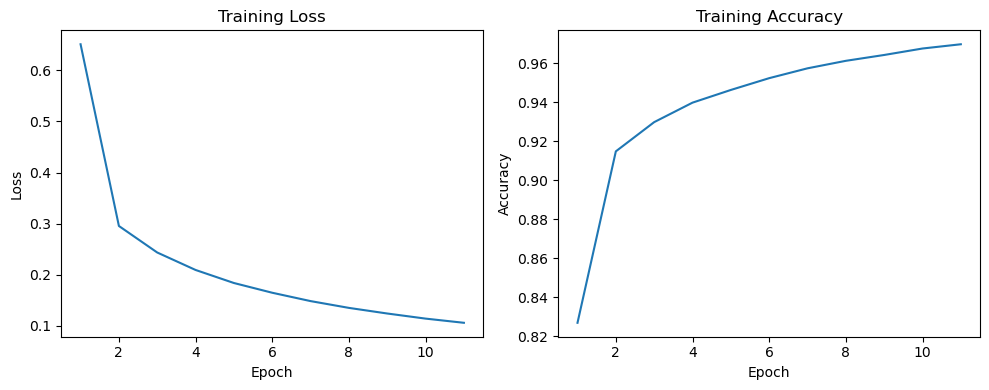

In [18]:
# f. Plot the training loss and accuracy
epochs = range(1, len(history.history["loss"]) + 1)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs, history.history["loss"])
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.subplot(1, 2, 2)
plt.plot(epochs, history.history["accuracy"])
plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.tight_layout()
plt.show()
